# Karyotype inference and simulated C-banding/FISH for *Capra hircus*

Inputs: frozen tables in `data/input_from_repo1/` (see `SOURCE.md`). Everything cytogenetic here is **simulated**. Assumptions: `docs/ASSUMPTIONS.md`.

| Stage | Question |
|---|---|
| 1. Inference | Q1: what karyotype and heteromorphisms does the sequence predict? |
| 2. Robustness | Q2: how far can it be trusted? |
| 3. Simulation | Q3: which design would detect them? |

## 0. Setup and input checks

In [1]:
import hashlib, re
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
IN, OUT, FIG = ROOT/'data/input_from_repo1', ROOT/'data/outputs', ROOT/'figures'
OUT.mkdir(exist_ok=True); FIG.mkdir(exist_ok=True)

# the inputs must be byte-identical to what SOURCE.md records
expected = dict(re.findall(r'\| (\S+\.(?:csv|json)) \| ([0-9a-f]{64}) \|', (IN/'SOURCE.md').read_text()))
for name, sha in expected.items():
    assert hashlib.sha256((IN/name).read_bytes()).hexdigest() == sha, f'checksum mismatch: {name}'
print(len(expected), 'input files verified')

6 input files verified


In [2]:
# One table with the same columns for the five haplotypes.
# IMCG (T2T, P, M) come from centromeres_master.csv; Kiko x Saanen from their own files.
master = pd.read_csv(IN/'centromeres_master.csv').rename(columns={'centromere_side': 'side'})
parts = [master]
for h in ('KikoP', 'SaanenM'):
    parts.append(pd.read_csv(IN/f'{h}_centromeres.csv'))
cols = ['hap', 'chr', 'kind', 'length', 'side', 'cen_start', 'cen_end', 'cen_len', 'sat_bp', 'sat_frac', 'complete', 'low_satellite']
H = pd.concat([p[cols] for p in parts], ignore_index=True)
H['complete'] = H.complete.astype(bool); H['low_satellite'] = H.low_satellite.astype(bool)

# Blocks that are not used as ground truth anywhere (see SOURCE.md and docs/ASSUMPTIONS.md)
H['excluded'] = H.low_satellite | ~H.complete | ((H.hap == 'SaanenM') & (H.chr == 'CHI5'))
# Blocks kept but marked: large SatI expansions of uncertain origin (real, or an assembler duplication)
DOUBTFUL = {('KikoP', 'CHI14'), ('SaanenM', 'CHI7'), ('SaanenM', 'CHI15')}
H['doubtful'] = [(a, b) in DOUBTFUL for a, b in zip(H.hap, H.chr)]
H['chr_n'] = H.chr.str.replace('CHI', '').replace({'X': '30'}).astype(int)
H.groupby('hap').agg(chromosomes=('chr', 'size'), excluded=('excluded', 'sum'), doubtful=('doubtful', 'sum'))

,chromosomes,excluded,doubtful
hap,,,
KikoP,30,0,1
M,30,8,0
P,29,9,0
SaanenM,30,1,2
T2T,30,0,0


## 1. Inference (Q1)

### 1a. Karyotype table

For each chromosome and haplotype:
- **Relative length**: percent of the summed length of the 29 autosomes of that haplotype (the X is expressed on the same base, so it is comparable across haplotypes even where the X is absent from the assembly).
- **Centromere position**: the middle of the satellite block, measured from the satellite end (the tables are already in that frame: `cen_start` is the distance from that end, and `side` only says whether it is the left or the right end of the deposited sequence). Because the block is a domain of several Mb and not a point, this is an approximation. The distance from the end to the start of the block is kept too.
- **Centromeric index** = short arm / length, **arm ratio** r = long arm / short arm, and the class of Levan et al. (1964): r = 1.0-1.7 metacentric, 1.7-3.0 submetacentric, 3.0-7.0 subterminal, above 7.0 terminal.

In a goat all the autosomes and the X are acrocentric, so the classes carry almost no information. The table is here to check that, and to show the X, the only chromosome with a real short arm.

In [3]:
def levan(r):
    return 'm' if r < 1.7 else 'sm' if r < 3.0 else 'st' if r < 7.0 else 't'

K = H.copy()
# cen_start / cen_end are measured from the satellite end of the chromosome (oriented frame), in every assembly:
# 'side' only records which end of the *deposited* sequence that is (L or R), so it is not used here.
# (the only autosome block that starts farther is P-CHI28, a 0.25-Mb fragment of an incomplete block, already excluded)
assert (K[(K.kind == 'autosome') & ~K.excluded].cen_start < 0.1e6).all(), 'usable autosome blocks should start within 0.1 Mb of the end'
mid = (K.cen_start + K.cen_end) / 2
K['p_to_start'] = K.cen_start                                                       # end -> start of the block
K['p'] = mid                                                                        # end -> middle of the block
K['q'] = K.length - K.p
K['CI'] = K.p / K.length
K['arm_ratio'] = K.q / K.p
K['levan'] = K.arm_ratio.map(levan)
auto_sum = K[K.kind == 'autosome'].groupby('hap').length.sum()
K['rel_length_pct'] = 100 * K.length / K.hap.map(auto_sum)
K['rank_by_size'] = K.groupby('hap').length.rank(ascending=False).astype(int)
for c in ('length', 'cen_start', 'cen_end', 'cen_len', 'p', 'p_to_start'):
    K[c + '_Mb'] = K[c] / 1e6

karyotype = K[['hap', 'chr', 'kind', 'length_Mb', 'rel_length_pct', 'rank_by_size', 'side', 'cen_len_Mb',
               'p_to_start_Mb', 'p_Mb', 'CI', 'arm_ratio', 'levan', 'complete', 'low_satellite', 'excluded', 'doubtful']]
karyotype.round(4).to_csv(OUT/'karyotype_inferred.csv', index=False)

summ = karyotype.groupby(['hap', 'kind']).agg(n=('chr', 'size'), CI_min=('CI', 'min'), CI_max=('CI', 'max'),
                                              arm_ratio_min=('arm_ratio', 'min'),
                                              classes=('levan', lambda s: dict(s.value_counts()))).round(3)
summ

n  CI_min  CI_max  arm_ratio_min    classes
hap     kind                                                  
KikoP   X          1   0.052   0.052         18.234   {'t': 1}
        autosome  29   0.023   0.072         12.841  {'t': 29}
M       X          1   0.053   0.053         17.891   {'t': 1}
        autosome  29   0.006   0.082         11.168  {'t': 29}
P       autosome  29   0.018   0.087         10.469  {'t': 29}
SaanenM X          1   0.053   0.053         17.880   {'t': 1}
        autosome  29   0.021   0.087         10.541  {'t': 29}
T2T     X          1   0.053   0.053         17.891   {'t': 1}
        autosome  29   0.021   0.082         11.187  {'t': 29}

In [4]:
t = karyotype[karyotype.hap == 'T2T'].set_index('chr')
print('T2T size order (top 5):', ', '.join(f'{c} {r:.2f} %' for c, r in t.rel_length_pct.nlargest(5).items()))
print('T2T X: short arm (end -> middle of block) = %.2f Mb, CI = %.3f, arm ratio = %.1f, end -> start of block = %.2f Mb'
      % (t.loc['CHIX', 'p_Mb'], t.loc['CHIX', 'CI'], t.loc['CHIX', 'arm_ratio'], t.loc['CHIX', 'p_to_start_Mb']))
a = t[t.kind == 'autosome']
print('T2T autosomes: end -> start of block up to %.3f Mb; end -> middle of block %.2f-%.2f Mb' % (a.p_to_start_Mb.max(), a.p_Mb.min(), a.p_Mb.max()))

T2T size order (top 5): CHI1 6.17 %, CHI2 5.47 %, CHIX 5.36 %, CHI3 4.92 %, CHI5 4.74 %
T2T X: short arm (end -> middle of block) = 7.66 Mb, CI = 0.053, arm ratio = 17.9, end -> start of block = 7.23 Mb
T2T autosomes: end -> start of block up to 0.047 Mb; end -> middle of block 1.97-5.23 Mb


### 1b. Idiogram

The 30 chromosomes of T2T-goat2.0, in order of size, drawn to scale. The satellite block is the shaded part; it is what a C-band would be expected to mark. The block is the operational centromere of the sequence repository (satellite domain, not CENP-A), so this is a map of where heterochromatin could be, not a prediction of a real band.

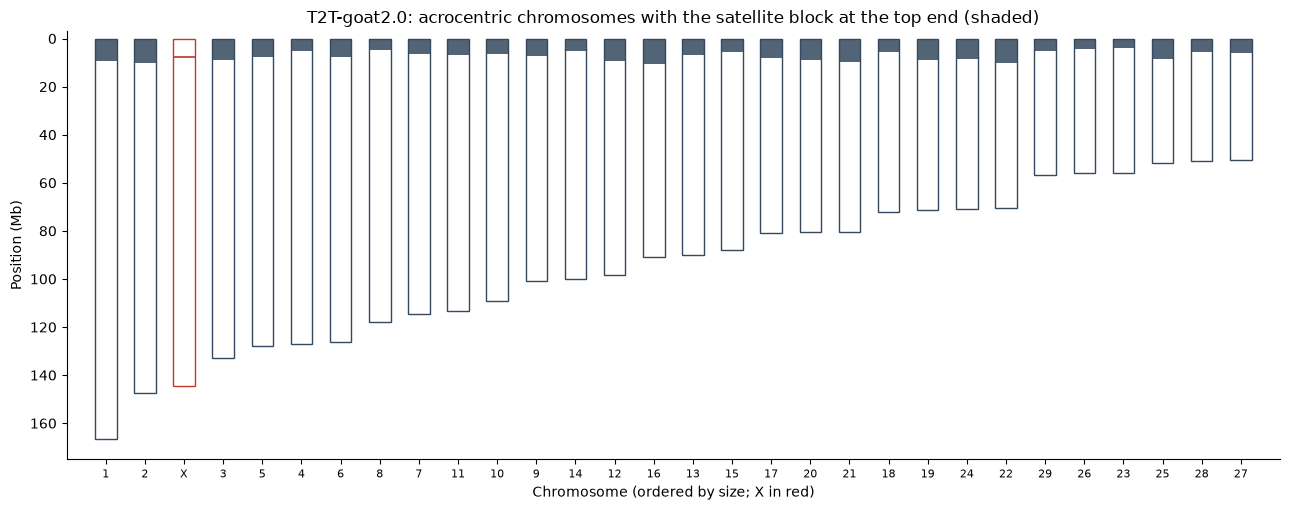

In [5]:
t = karyotype[karyotype.hap == 'T2T'].sort_values('length_Mb', ascending=False).reset_index(drop=True)
Kt = K[K.hap == 'T2T'].set_index('chr')
fig, ax = plt.subplots(figsize=(13, 5.2))
w = 0.55
for i, r in t.iterrows():
    L = r.length_Mb; s, e = Kt.loc[r.chr, 'cen_start_Mb'], Kt.loc[r.chr, 'cen_end_Mb']
    col = '#c0392b' if r.chr == 'CHIX' else '#34495e'
    ax.add_patch(plt.Rectangle((i - w/2, 0), w, L, fc='white', ec=col, lw=1))
    ax.add_patch(plt.Rectangle((i - w/2, s), w, e - s, fc=col, alpha=.85, lw=0))   # satellite block (left end of the sequence)
ax.set_xlim(-1, len(t)); ax.set_ylim(175, -3)                                      # ends at the top = start of the sequence
ax.set_xticks(range(len(t))); ax.set_xticklabels(t.chr.str.replace('CHI', ''), fontsize=8)
ax.set_xlabel('Chromosome (ordered by size; X in red)'); ax.set_ylabel('Position (Mb)')
ax.set_title('T2T-goat2.0: acrocentric chromosomes with the satellite block at the top end (shaded)')
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); fig.savefig(FIG/'idiogram_T2T.png', dpi=150); plt.show()

### 1c. Expected heteromorphisms

A heteromorphism here is a difference in the size of the block between the two homologs of a pair. Two pairs of haplotypes are used, kept separate:

- **IMCG P / M**: the two haplotypes of one animal (the male of the reference assembly). The X is not in P, so there are 29 autosome pairs at most.
- **KikoP / SaanenM**: the two haplotypes of an F1 female whose parents are of two breeds, so the difference mixes individual and breed. It is labelled "between breeds", not "within an animal".

The measure is d = |ln(block_a / block_b)|, and the absolute difference in Mb. A pair is usable only if both blocks are complete and not `low_satellite`, and Saanen CHI5 is left out. Pairs that include a doubtful block are kept and marked.

The size classes are conventions of this analysis, not of nature: d < 0.18 small (below about 20 %, the same threshold that the simulation will use as the definition of a true heteromorphism), 0.18-0.50 moderate, above 0.50 large.

In [6]:
PAIRS = {'IMCG P / M': ('P', 'M', 'within IMCG'), 'KikoP / SaanenM': ('KikoP', 'SaanenM', 'between breeds (Kiko x Saanen)')}
S = K.set_index(['hap', 'chr'])
rows = []
for name, (a, b, label) in PAIRS.items():
    for chrom in sorted(set(S.loc[a].index) & set(S.loc[b].index), key=lambda c: int(c.replace('CHI', '').replace('X', '30'))):
        ra, rb = S.loc[(a, chrom)], S.loc[(b, chrom)]
        rows.append(dict(pair=name, comparison=label, chr=chrom, kind=ra.kind,
                         cen_a_Mb=ra.cen_len_Mb, cen_b_Mb=rb.cen_len_Mb,
                         abs_diff_Mb=abs(ra.cen_len - rb.cen_len) / 1e6,
                         d_cen=abs(np.log(ra.cen_len / rb.cen_len)),
                         d_rest=abs(np.log((ra.length - ra.cen_len) / (rb.length - rb.cen_len))),
                         usable=not (ra.excluded or rb.excluded),
                         doubtful=bool(ra.doubtful or rb.doubtful),
                         why_not=', '.join(f'{h} {c}: ' + ('low_satellite' if S.loc[(h, c)].low_satellite else 'gap/incomplete' if not S.loc[(h, c)].complete else 'cut by window')
                                           for h, c in ((a, chrom), (b, chrom)) if S.loc[(h, c)].excluded)))
het = pd.DataFrame(rows)
het['size_class'] = np.where(~het.usable, 'excluded', pd.cut(het.d_cen, [-1, .18, .5, 99], labels=['small', 'moderate', 'large']).astype(str))
het.round(4).to_csv(OUT/'expected_heteromorphisms.csv', index=False)

u = het[het.usable]
summary = u.groupby('pair').agg(n_usable=('chr', 'size'), n_doubtful=('doubtful', 'sum'),
                                median_d_cen=('d_cen', 'median'), median_d_rest=('d_rest', 'median'),
                                median_abs_diff_Mb=('abs_diff_Mb', 'median'),
                                small=('size_class', lambda s: (s == 'small').sum()),
                                moderate=('size_class', lambda s: (s == 'moderate').sum()),
                                large=('size_class', lambda s: (s == 'large').sum())).round(3)
summary

,n_usable,n_doubtful,median_d_cen,median_d_rest,median_abs_diff_Mb,small,moderate,large
pair,,,,,,,,
IMCG P / M,16,0,0.371,0.001,2.671,5,6,5
KikoP / SaanenM,29,3,0.165,0.002,1.088,17,11,1


In [7]:
print('Excluded or not comparable:')
print(het[~het.usable][['pair', 'chr', 'why_not']].to_string(index=False))
print()
print('Usable pairs that include a doubtful block:')
print(het[het.usable & het.doubtful][['pair', 'chr', 'cen_a_Mb', 'cen_b_Mb', 'd_cen', 'size_class']].round(2).to_string(index=False))

Excluded or not comparable:
           pair   chr                                          why_not
     IMCG P / M  CHI2   P CHI2: gap/incomplete, M CHI2: gap/incomplete
     IMCG P / M  CHI4                           P CHI4: gap/incomplete
     IMCG P / M  CHI7                            M CHI7: low_satellite
     IMCG P / M  CHI9                            M CHI9: low_satellite
     IMCG P / M CHI10 P CHI10: gap/incomplete, M CHI10: gap/incomplete
     IMCG P / M CHI11                          P CHI11: gap/incomplete
     IMCG P / M CHI17                          P CHI17: gap/incomplete
     IMCG P / M CHI20                          M CHI20: gap/incomplete
     IMCG P / M CHI22                          M CHI22: gap/incomplete
     IMCG P / M CHI23 P CHI23: gap/incomplete, M CHI23: gap/incomplete
     IMCG P / M CHI27                          P CHI27: gap/incomplete
     IMCG P / M CHI28                          P CHI28: gap/incomplete
     IMCG P / M CHI29  P CHI29: gap/incomplete, M

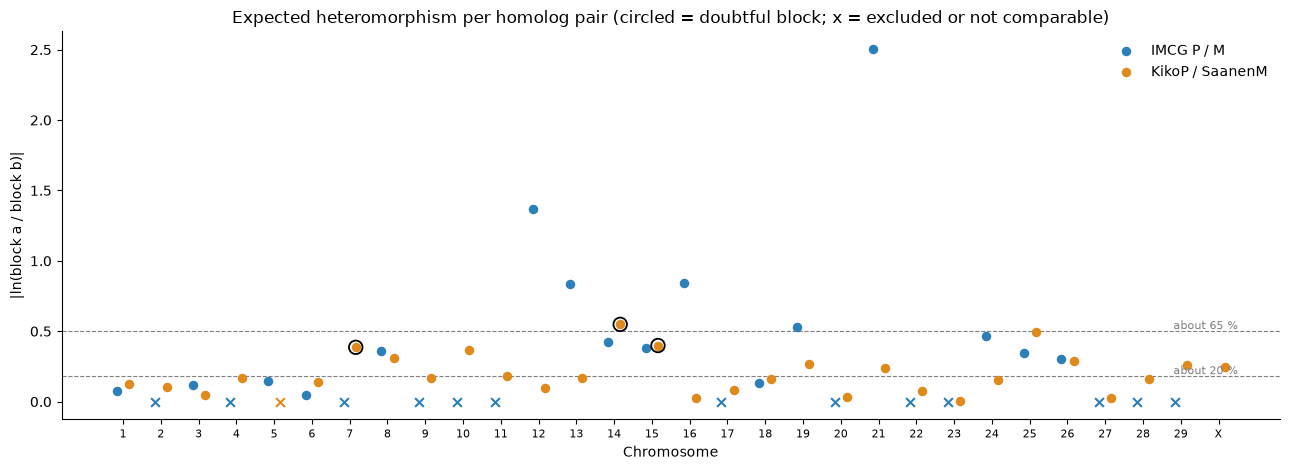

In [8]:
fig, ax = plt.subplots(figsize=(13, 4.8))
order = [f'CHI{i}' for i in range(1, 30)] + ['CHIX']
colors = {'IMCG P / M': '#2c7fb8', 'KikoP / SaanenM': '#e08a1e'}
for k, (name, g) in enumerate(het.groupby('pair')):
    off = (k - .5) * .32
    g = g.set_index('chr').reindex(order)
    ok = g[g.usable.fillna(False).astype(bool)]
    ax.scatter([order.index(c) + off for c in ok.index], ok.d_cen, s=34, color=colors[name], label=name, zorder=3)
    dd = ok[ok.doubtful]
    ax.scatter([order.index(c) + off for c in dd.index], dd.d_cen, s=95, facecolor='none', edgecolor='black', lw=1.3, zorder=4)
    bad = g[g.usable.eq(False)]
    ax.scatter([order.index(c) + off for c in bad.index], [0.0] * len(bad), marker='x', s=40, color=colors[name], zorder=3)
for y, lab in ((.18, 'about 20 %'), (.5, 'about 65 %')):
    ax.axhline(y, color='gray', ls='--', lw=.8); ax.text(len(order) - .5, y + .015, lab, ha='right', fontsize=8, color='gray')
ax.set_xticks(range(len(order))); ax.set_xticklabels([c.replace('CHI', '') for c in order], fontsize=8)
ax.set_xlabel('Chromosome'); ax.set_ylabel('|ln(block a / block b)|')
ax.set_title('Expected heteromorphism per homolog pair (circled = doubtful block; x = excluded or not comparable)')
ax.legend(frameon=False)
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); fig.savefig(FIG/'expected_heteromorphisms.png', dpi=150); plt.show()

### What stage 1 says

Read the two tables above together with the figure. The cell below prints the numbers that the README and the next stages quote, taken from the tables and not typed by hand.

In [9]:
t = karyotype[karyotype.hap == 'T2T']
print('Classes in T2T:', {k: int(v) for k, v in t.levan.value_counts().items()})
print('Autosomes: CI from %.3f to %.3f; X: CI = %.3f' % (t[t.kind == 'autosome'].CI.min(), t[t.kind == 'autosome'].CI.max(), t[t.kind == 'X'].CI.iloc[0]))
for name, r in summary.iterrows():
    print(f'{name}: {int(r.n_usable)} usable pairs; median |ln ratio| = {r.median_d_cen:.2f} in the block against {r.median_d_rest:.3f} in the rest; '
          f'median difference {r.median_abs_diff_Mb:.2f} Mb; small/moderate/large = {int(r.small)}/{int(r.moderate)}/{int(r.large)}')

Classes in T2T: {'t': 30}
Autosomes: CI from 0.021 to 0.082; X: CI = 0.053
IMCG P / M: 16 usable pairs; median |ln ratio| = 0.37 in the block against 0.001 in the rest; median difference 2.67 Mb; small/moderate/large = 5/6/5
KikoP / SaanenM: 29 usable pairs; median |ln ratio| = 0.17 in the block against 0.002 in the rest; median difference 1.09 Mb; small/moderate/large = 17/11/1


## 2. Robustness (Q2)

Stage 1 already leaves out the blocks that are incomplete, `low_satellite` or cut by the window. Here the remaining pairs are tested against two things that could make a difference look bigger or smaller than it is:

1. **Doubtful blocks.** Kiko CHI14 and Saanen CHI7 and CHI15 have large SatI expansions of uncertain origin (real, or a duplication made by the assembler). They are removed in one scenario.
2. **What is measured.** The block length includes 15-55 % of non-satellite sequence (the spacer between merged pieces). Repeating the comparison with the satellite base pairs only (`sat_bp`) shows whether the difference is in the satellite or in the spacer. The sequence repository lists this check as pending for its homolog test.

Each usable pair gets a label. It is **firm** if it is not a doubtful block, the two measures agree to within 0.2 in |ln ratio| (about the same 20 % used as the smallest difference worth calling), and the same haplotype is the larger one in both (this last check only counts when both differences are at least 0.1, because below that the direction is noise). Otherwise it is **doubtful**, and the reason is recorded. Excluded pairs keep their stage 1 reason. The 0.2 and 0.1 are conventions of this analysis. A fixed class boundary was tried first and rejected as a rule, because pairs just above or below 0.18 changed class with tiny shifts.

In [10]:
LAB = ['small', 'moderate', 'large']
bins = lambda x: pd.cut(x, [-1, .18, .5, 99], labels=LAB).astype(str)

R = het[['pair', 'comparison', 'chr', 'kind', 'usable', 'doubtful', 'why_not', 'd_cen', 'abs_diff_Mb', 'size_class']].rename(
    columns={'d_cen': 'd_block', 'abs_diff_Mb': 'abs_diff_block_Mb', 'size_class': 'class_block'}).copy()
for i, r in R.iterrows():
    a, b, _ = PAIRS[r.pair]
    ra, rb = S.loc[(a, r.chr)], S.loc[(b, r.chr)]
    R.loc[i, 'd_sat'] = abs(np.log(ra.sat_bp / rb.sat_bp))
    R.loc[i, 'abs_diff_sat_Mb'] = abs(ra.sat_bp - rb.sat_bp) / 1e6
    R.loc[i, 'bigger_block'] = a if ra.cen_len > rb.cen_len else b
    R.loc[i, 'bigger_sat'] = a if ra.sat_bp > rb.sat_bp else b
    R.loc[i, 'min_sat_frac'] = min(ra.sat_frac, rb.sat_frac)
R['class_sat'] = np.where(R.usable, bins(R.d_sat), 'excluded')

AGREE, DIR_MIN = 0.2, 0.1
def why(r):
    if not r.usable: return 'excluded: ' + r.why_not
    out = []
    if r.doubtful: out.append('doubtful block')
    if abs(r.d_block - r.d_sat) > AGREE: out.append(f'block {r.d_block:.2f} vs satellite only {r.d_sat:.2f}')
    if r.bigger_block != r.bigger_sat and min(r.d_block, r.d_sat) >= DIR_MIN: out.append('larger haplotype changes with satellite only')
    return '; '.join(out)
R['reason'] = R.apply(why, axis=1)
R['status'] = np.where(~R.usable, 'excluded', np.where(R.reason == '', 'firm', 'doubtful'))
R.drop(columns=['why_not']).round(4).to_csv(OUT/'robustness_pairs.csv', index=False)
R[R.usable].groupby(['pair', 'status']).size().unstack(fill_value=0)

status,doubtful,firm
pair,,
IMCG P / M,1,15
KikoP / SaanenM,10,19


In [11]:
def scen(df, d, absd, name):
    g = df.groupby('pair').agg(n=('chr', 'size'), median_d=(d, 'median'), median_abs_diff_Mb=(absd, 'median'),
                               small=(d, lambda s: (s < .18).sum()), moderate=(d, lambda s: ((s >= .18) & (s < .5)).sum()),
                               large=(d, lambda s: (s >= .5).sum()))
    g.insert(0, 'scenario', name)
    return g.reset_index()

U = R[R.usable]
rob = pd.concat([scen(U, 'd_block', 'abs_diff_block_Mb', 'A. baseline (block length)'),
                 scen(U[~U.doubtful], 'd_block', 'abs_diff_block_Mb', 'B. without doubtful blocks'),
                 scen(U, 'd_sat', 'abs_diff_sat_Mb', 'C. satellite only (sat_bp)'),
                 scen(U[~U.doubtful], 'd_sat', 'abs_diff_sat_Mb', 'D. satellite only, without doubtful'),
                 scen(U[U.status == 'firm'], 'd_block', 'abs_diff_block_Mb', 'E. firm pairs only (block length)')],
                ignore_index=True).sort_values(['pair', 'scenario'])
rob.round(3).to_csv(OUT/'robustness_scenarios.csv', index=False)
rob.round(3)

,pair,scenario,n,median_d,median_abs_diff_Mb,small,moderate,large
0,IMCG P / M,A. baseline (block length),16,0.371,2.671,5,6,5
2,IMCG P / M,B. without doubtful blocks,16,0.371,2.671,5,6,5
4,IMCG P / M,C. satellite only (sat_bp),16,0.370,1.740,4,7,5
6,IMCG P / M,"D. satellite only, without doubtful",16,0.370,1.740,4,7,5
8,IMCG P / M,E. firm pairs only (block length),15,0.380,2.905,4,6,5
1,KikoP / SaanenM,A. baseline (block length),29,0.165,1.088,17,11,1
3,KikoP / SaanenM,B. without doubtful blocks,26,0.162,1.047,17,9,0
5,KikoP / SaanenM,C. satellite only (sat_bp),29,0.270,1.350,12,14,3
7,KikoP / SaanenM,"D. satellite only, without doubtful",26,0.216,1.054,12,12,2
9,KikoP / SaanenM,E. firm pairs only (block length),19,0.166,0.952,11,8,0


In [12]:
from scipy import stats
for name, g in U.groupby('pair'):
    rho = stats.spearmanr(g.d_block, g.d_sat)
    print(f'{name}: Spearman between d(block) and d(satellite only) = {rho.statistic:.2f} (n={len(g)}); '
          f'class unchanged in {(g.class_block == g.class_sat).sum()} of {len(g)}; larger haplotype unchanged in {(g.bigger_block == g.bigger_sat).sum()} of {len(g)}')
print()
print(U.groupby('pair').status.value_counts().unstack(fill_value=0))
print()
print('Doubtful usable pairs and why:')
print(U[U.status == 'doubtful'][['pair', 'chr', 'd_block', 'd_sat', 'reason']].round(2).to_string(index=False))
print()
print('How much of the block is satellite in the pairs used (min of the two haplotypes): median %.2f, range %.2f-%.2f' % (U.min_sat_frac.median(), U.min_sat_frac.min(), U.min_sat_frac.max()))

IMCG P / M: Spearman between d(block) and d(satellite only) = 0.88 (n=16); class unchanged in 13 of 16; larger haplotype unchanged in 16 of 16
KikoP / SaanenM: Spearman between d(block) and d(satellite only) = 0.49 (n=29); class unchanged in 18 of 29; larger haplotype unchanged in 25 of 29

status           doubtful  firm
pair                           
IMCG P / M              1    15
KikoP / SaanenM        10    19

Doubtful usable pairs and why:
           pair   chr  d_block  d_sat                                                                          reason
     IMCG P / M  CHI5     0.15   0.38                                               block 0.15 vs satellite only 0.38
KikoP / SaanenM  CHI3     0.05   0.27                                               block 0.05 vs satellite only 0.27
KikoP / SaanenM  CHI6     0.14   0.52                                               block 0.14 vs satellite only 0.52
KikoP / SaanenM  CHI7     0.39   0.45                                       

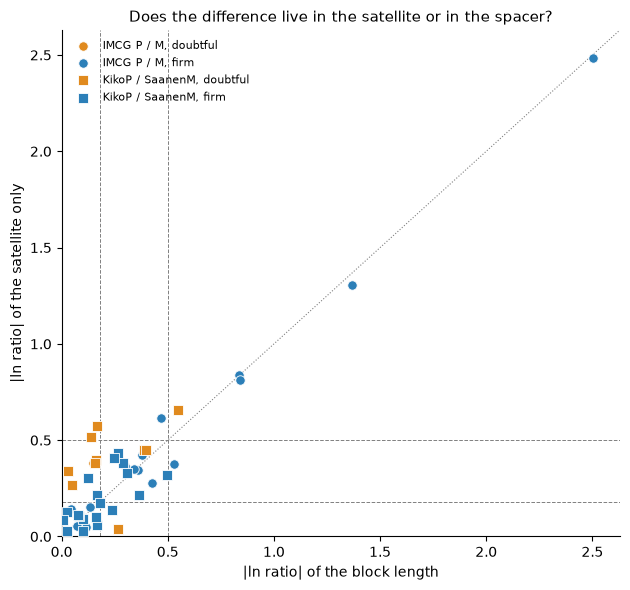

In [13]:
fig, ax = plt.subplots(figsize=(6.4, 6))
mk = {'IMCG P / M': 'o', 'KikoP / SaanenM': 's'}; sc = {'firm': '#2c7fb8', 'doubtful': '#e08a1e'}
for (pair, status), g in U.groupby(['pair', 'status']):
    ax.scatter(g.d_block, g.d_sat, marker=mk[pair], s=46, color=sc[status], edgecolor='white', lw=.6, label=f'{pair}, {status}', zorder=3)
lim = max(U.d_block.max(), U.d_sat.max()) * 1.05
ax.plot([0, lim], [0, lim], color='gray', lw=.8, ls=':')
for v in (.18, .5):
    ax.axvline(v, color='gray', lw=.7, ls='--'); ax.axhline(v, color='gray', lw=.7, ls='--')
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('|ln ratio| of the block length'); ax.set_ylabel('|ln ratio| of the satellite only')
ax.set_title('Does the difference live in the satellite or in the spacer?', fontsize=11)
ax.legend(frameon=False, fontsize=8, loc='upper left')
for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
plt.tight_layout(); fig.savefig(FIG/'robustness_block_vs_satellite.png', dpi=150); plt.show()

## 3. Simulation (Q3)

The simulator is the one built for the earlier version of the project (`Capra_hircus_analysis.ipynb`, section 3.5), reused with its structure: six females, 29 autosomes and the X, two homologs each, many metaphases per animal, vectorised in numpy. What changed:

- **Ground truth** is rebuilt from the four haplotypes (stage 1 filters: complete, not `low_satellite`, Saanen CHI5 out). Before, it came from P and M only.
- **Heteromorphism spread** is estimated from the **firm** pairs of each animal, kept as two scenarios: `IMCG-like` (P/M) and `Kiko x Saanen-like` (between breeds). Before, a single P-M estimate was used, which may include assembly artefacts.
- **Optical resolution** is a parameter. A band is measurable only if it is at least that large, and the absolute error of its size is one third of it. Before, the limit was fixed at 0.05 µm.
- **Scale and band** K (µm per Mb) and F (band size as a multiple of the block) are varied (`docs/ASSUMPTIONS.md`), together with measurement error and number of metaphases.
- The mixed model is not used: with six animals it did not converge in the earlier version, so the slope is fitted by regression with errors robust by chromosome.

Three analyses, as before: **(1)** slope of ln(C-band) on ln(remaining length), reported as bias against the true slope of the same data; **(2)** the heteromorphism criterion of the original project (a difference of more than `TAU_CALL` in more than half of the metaphases, with the same sign), scored against a true heteromorphism of |ln ratio| above 0.18, giving sensitivity, specificity and power by size of the true difference; **(3)** Spearman correlation, across the 30 chromosomes, between the measurement and the sequence, with the ceiling that biological variation alone allows. The headline is (2).

Everything here is **simulated**: it says what a design could detect under these assumptions, not what a goat shows.

In [14]:
import os, time
from scipy import stats
import warnings; warnings.filterwarnings('ignore', category=RuntimeWarning)

SEED = 20261016
N_REP = int(os.environ.get('CAPRA_NREP', 300))          # CAPRA_NREP=20 for a quick test
KINDS_SAT = ['SatI', 'SatII', 'SatIII']

# satellite families by block, for the four haplotypes
fam = pd.concat([p[['hap', 'chr', 'SatI', 'SatII', 'SatIII']] for p in parts], ignore_index=True)
T3 = H.merge(fam, on=['hap', 'chr']); T3['rest'] = T3.length - T3.cen_len
chr_list = list(T3[T3.hap == 'T2T'].sort_values('length', ascending=False).chr); C = len(chr_list)
FOUR = ['P', 'M', 'KikoP', 'SaanenM']
gmean = lambda x: float(np.exp(np.log(x).mean()))

def build_truth(drop_doubtful=False):
    # per chromosome: geometric mean over the usable haplotypes (T2T is the collapsed assembly of the IMCG animal: not averaged in, only a fallback)
    rows = []
    for c in chr_list:
        g = T3[(T3.chr == c) & T3.hap.isin(FOUR) & ~T3.excluded & ~(T3.doubtful & drop_doubtful)]
        t2t = T3[(T3.hap == 'T2T') & (T3.chr == c)]
        src = g if len(g) else t2t
        r = dict(chr=c, kind=t2t.kind.iloc[0], n_haplotypes_used=len(g), T2T_fallback=not len(g),
                 cen_Mb=gmean(src.cen_len) / 1e6, rest_Mb=gmean(src.rest) / 1e6)
        for k in KINDS_SAT:       # a family absent from a chromosome (SatIII in 6) stays at the T2T value, as in the earlier version
            r[k + '_Mb'] = (gmean(src[k]) if (src[k] > 0).all() else float(t2t[k].iloc[0])) / 1e6
        rows.append(r)
    return pd.DataFrame(rows)

truth = build_truth()
truth.round(4).to_csv(OUT/'sim_ground_truth.csv', index=False)
print(f'{C} chromosomes; haplotypes used per chromosome: min {truth.n_haplotypes_used.min()}, median {int(truth.n_haplotypes_used.median())}; '
      f'T2T fallback in {int(truth.T2T_fallback.sum())}')
truth.groupby('n_haplotypes_used').size().rename('chromosomes')

30 chromosomes; haplotypes used per chromosome: min 2, median 3; T2T fallback in 0


n_haplotypes_used
2     4
3    11
4    15
Name: chromosomes, dtype: int64

In [15]:
# Spread of the true difference between homologs, from the pairs of stage 2.
# The ln ratio of two homologs ~ N(0, sqrt(2) * sigma); the sign of a pair is arbitrary, so use the median of |ln ratio| / 0.6745.
sigma_hom = lambda d: float(np.median(d) / 0.6745 / np.sqrt(2))
Uh = R[R.usable].merge(het[['pair', 'chr', 'd_rest']], on=['pair', 'chr'])
rows = []
for pair, label in (('IMCG P / M', 'IMCG-like'), ('KikoP / SaanenM', 'Kiko x Saanen-like')):
    for sel, name in ((Uh.status == 'firm', 'firm pairs'), (Uh.status != 'x', 'all usable pairs')):
        g = Uh[(Uh.pair == pair) & sel]
        rows.append(dict(het=label, based_on=name, n=len(g), sigma_cen=sigma_hom(g.d_block), sigma_rest=max(sigma_hom(g.d_rest), 0.005)))
SIG = pd.DataFrame(rows); SIG.round(3).to_csv(OUT/'sim_het_sigma.csv', index=False)
SIG_HET = {r.het: (r.sigma_cen, r.sigma_rest) for r in SIG[SIG.based_on == 'firm pairs'].itertuples()}
SIG.round(3)

,het,based_on,n,sigma_cen,sigma_rest
0,IMCG-like,firm pairs,15,0.399,0.005
1,IMCG-like,all usable pairs,16,0.389,0.005
2,Kiko x Saanen-like,firm pairs,19,0.174,0.005
3,Kiko x Saanen-like,all usable pairs,29,0.173,0.005


In [16]:
# ---------------- simulator ----------------
PAR = dict(N_ANIMALS=6, SIG_COND=0.10, SIG_LEN_MEAS=0.05, SIG_IND_CEN=0.10, SIG_IND_REST=0.02, SIG_COMP=0.08,
           SIG_FISH=0.25, FISH_MIN_PERMIL=0.10, P_DROP=0.07, TAU_CALL=0.25, MAJ=0.50, TAU_TRUE=0.18)
GAIN = np.array([1.0, 1.4, 3.0])           # FISH signal gain per probe (SatI, SatII, SatIII)
ABS_FRAC_OF_RES = 1 / 3                    # absolute error of the band size, as a fraction of the optical resolution
EDGES = [0, 0.1, 0.18, 0.3, 0.5, 0.8, 5]
T2T_T = T3[T3.hap == 'T2T'].set_index('chr').loc[chr_list]
REAL_CEN, REAL_BP = T2T_T.cen_len.values, T2T_T[KINDS_SAT].values       # sequence values to correlate against

def arrays(tr):
    return (tr.cen_Mb.values, tr.rest_Mb.values, tr[[k + '_Mb' for k in KINDS_SAT]].values)

def simulate(rng, tr, K, F, res, sig_band, M, sig_het_cen, sig_het_rest, A=PAR['N_ANIMALS']):
    B_cen, B_rest, B_bp = arrays(tr)
    ind_c, ind_r = rng.normal(0, PAR['SIG_IND_CEN'], (A, C, 1)), rng.normal(0, PAR['SIG_IND_REST'], (A, C, 1))
    het_c, het_r = rng.normal(0, sig_het_cen, (A, C, 2)), rng.normal(0, sig_het_rest, (A, C, 2))
    cen_t, rest_t = B_cen[None, :, None] * np.exp(ind_c + het_c), B_rest[None, :, None] * np.exp(ind_r + het_r)           # (A,C,2) Mb
    bp_t = B_bp[None, :, None, :] * (cen_t / B_cen[None, :, None])[..., None] * np.exp(rng.normal(0, PAR['SIG_COMP'], (A, C, 2, 3)))
    cond = np.exp(rng.normal(0, PAR['SIG_COND'], (A, M, 1, 1)))
    scored = rng.random((A, M, C, 1)) > PAR['P_DROP']
    band = K * F * cen_t[:, None] * cond * np.exp(rng.normal(0, sig_band, (A, M, C, 2))) + rng.normal(0, res * ABS_FRAC_OF_RES, (A, M, C, 2))
    length = K * (rest_t + cen_t)[:, None] * cond * np.exp(rng.normal(0, PAR['SIG_LEN_MEAS'], (A, M, C, 2)))
    rest_um = length - band
    ok = scored & (band >= res) & (rest_um > 0)                      # a band smaller than the optical resolution cannot be measured
    sig = bp_t[:, None] * GAIN * np.exp(rng.normal(0, PAR['SIG_FISH'], (A, M, C, 2, 3))); sig = np.where(scored[..., None], sig, np.nan)
    share = 1000 * sig / np.nansum(sig, axis=(2, 3), keepdims=True); share = np.where(share < PAR['FISH_MIN_PERMIL'], 0.0, share)
    return dict(A=A, M=M, K=K, F=F, cen_t=cen_t, rest_t=rest_t, bp_t=bp_t, band=band, length=length, rest_um=rest_um, ok=ok, share=share)

def ols_cluster(x, y, g):
    # slope and standard error robust by chromosome (CR1)
    X = np.column_stack([np.ones_like(x), x]); XtXi = np.linalg.inv(X.T @ X); beta = XtXi @ X.T @ y; e = y - X @ beta
    meat = np.zeros((2, 2)); gs = np.unique(g)
    for gi in gs:
        s = X[g == gi].T @ e[g == gi]; meat += np.outer(s, s)
    n, nG = len(x), len(gs)
    V = XtXi @ meat @ XtXi * (nG / (nG - 1)) * ((n - 1) / (n - 2)); return beta[1], np.sqrt(V[1, 1]), nG - 1

def analyze(s):
    A = s['A']; out = {}
    out['measurable'] = s['ok'].mean()                                # share of homolog bands that could be measured at all
    bm = np.nanmean(np.where(s['ok'], s['band'], np.nan), axis=1); rm = np.nanmean(np.where(s['ok'], s['rest_um'], np.nan), axis=1)   # (A,C,2)
    x, y = np.log(rm).ravel(), np.log(bm).ravel(); g = np.tile(np.arange(C)[None, :, None], (A, 1, 2)).ravel(); m = np.isfinite(x) & np.isfinite(y)
    b_true = np.polyfit(np.log(s['rest_t']).ravel(), np.log(s['cen_t']).ravel(), 1)[0]
    if m.sum() > 20 and len(np.unique(g[m])) > 5:
        b, se, df = ols_cluster(x[m], y[m], g[m]); out.update(slope_est=b, slope_true=b_true, bias=b - b_true, se=se)
    else:
        out.update(slope_est=np.nan, slope_true=b_true, bias=np.nan, se=np.nan)
    # heteromorphism (criterion of the project document) against the truth
    valid = s['ok'][..., 0] & s['ok'][..., 1]; d = np.log(s['band'][..., 0] / s['band'][..., 1])
    med = np.nanmedian(np.where(valid, d, np.nan), axis=1)
    rep = ((np.abs(d) > PAR['TAU_CALL']) & (np.sign(d) == np.sign(med)[:, None, :]) & valid).sum(1) / np.maximum(valid.sum(1), 1)
    call = rep > PAR['MAJ']                                           # a pair that could not be measured is never called
    true_d = np.abs(np.log(s['cen_t'][..., 0] / s['cen_t'][..., 1])); truth_h = true_d > PAR['TAU_TRUE']
    out.update(sens=call[truth_h].mean() if truth_h.any() else np.nan, spec=(~call[~truth_h]).mean() if (~truth_h).any() else np.nan,
               true_prevalence=truth_h.mean())
    for lo, hi in zip(EDGES[:-1], EDGES[1:]):
        sel = (true_d >= lo) & (true_d < hi); out[f'power_{lo}-{hi}'] = call[sel].mean() if sel.any() else np.nan
    # concordance with the sequence across chromosomes, and the ceiling without measurement error
    mb = np.nanmean(np.where(s['ok'], s['band'], np.nan), axis=(0, 1, 3))
    okc = np.isfinite(mb)
    out['rho_band'] = stats.spearmanr(mb[okc], REAL_CEN[okc]).statistic if okc.sum() > 3 else np.nan
    out['rho_ceiling'] = stats.spearmanr((s['K'] * s['F'] * s['cen_t']).mean(axis=(0, 2)), REAL_CEN).statistic
    fs = np.nanmean(s['share'], axis=(0, 1, 3))
    for j, k in enumerate(KINDS_SAT):
        sel = (REAL_BP[:, j] > 0) & (fs[:, j] > 0); out[f'rho_FISH_{k}'] = stats.spearmanr(fs[sel, j], REAL_BP[sel, j]).statistic if sel.sum() > 3 else np.nan
    return out

def run(tr, K, F, res, err, M, het_name, sig, rng):
    return analyze(simulate(rng, tr, K, F, res, err, M, sig[het_name][0], sig[het_name][1]))
print('simulator ready:', C, 'chromosomes;', PAR['N_ANIMALS'], 'animals')

simulator ready: 30 chromosomes; 6 animals


### 3a. Grid of scenarios

K (µm/Mb) {0.015, 0.03, 0.05} x F {1, 1.5, 2.5} x optical resolution {0.1, 0.25, 0.4} µm x measurement error {10, 20, 30 %} x metaphases {10, 20} x heteromorphism {IMCG-like, Kiko x Saanen-like}: 324 scenarios, `N_REP` replicates each. The ranges and their status are in `docs/ASSUMPTIONS.md`.

In [17]:
import itertools
GRID = list(itertools.product((0.015, 0.03, 0.05), (1.0, 1.5, 2.5), (0.1, 0.25, 0.4), (0.10, 0.20, 0.30), (10, 20), tuple(SIG_HET)))
t0 = time.time(); reps = []
for idx, (K_, F_, res_, err_, M_, het_) in enumerate(GRID):
    rng = np.random.default_rng([SEED, idx])                       # one stream per scenario: results do not depend on the order
    for r in range(N_REP):
        reps.append(dict(K=K_, F=F_, res=res_, error=err_, metaphases=M_, het=het_, rep=r, **run(truth, K_, F_, res_, err_, M_, het_, SIG_HET, rng)))
reps = pd.DataFrame(reps); reps['KF'] = (reps.K * reps.F).round(4)
print(f'{len(GRID)} scenarios x {N_REP} replicates in {time.time() - t0:.0f} s')
KEYS = ['K', 'F', 'KF', 'res', 'error', 'metaphases', 'het']
agg = reps.groupby(KEYS).agg(measurable=('measurable', 'mean'), sens=('sens', 'mean'), spec=('spec', 'mean'), true_prevalence=('true_prevalence', 'mean'),
                             slope_bias=('bias', 'mean'), rho_band=('rho_band', 'median'), rho_ceiling=('rho_ceiling', 'median'),
                             rho_FISH_SatI=('rho_FISH_SatI', 'median'), rho_FISH_SatII=('rho_FISH_SatII', 'median'), rho_FISH_SatIII=('rho_FISH_SatIII', 'median')).reset_index()
agg.round(4).to_csv(OUT/'sim_scenarios.csv', index=False)
pcols = [c for c in reps.columns if c.startswith('power_')]
power = reps.groupby(KEYS)[pcols].mean().reset_index(); power.round(4).to_csv(OUT/'sim_power_by_true_difference.csv', index=False)
agg.describe().loc[['min', '50%', 'max'], ['measurable', 'sens', 'spec', 'slope_bias', 'rho_band', 'rho_ceiling']].round(3)

324 scenarios x 300 replicates in 143 s


,measurable,sens,spec,slope_bias,rho_band,rho_ceiling
min,0.017,0.001,0.826,-0.196,-0.005,0.289
50%,0.665,0.442,0.940,0.095,0.287,0.324
max,0.918,0.848,1.000,0.265,0.343,0.345


### 3b. What the grid says

Power to call a heteromorphism, by the size of the true difference (|ln ratio| between the two homologs of an animal). The first bins hold the pairs that are not heteromorphic in truth, so the power there is the false-call rate. Heteromorphism depends only on the product K x F (the band size per Mb of block), so the scenarios that share it are pooled.

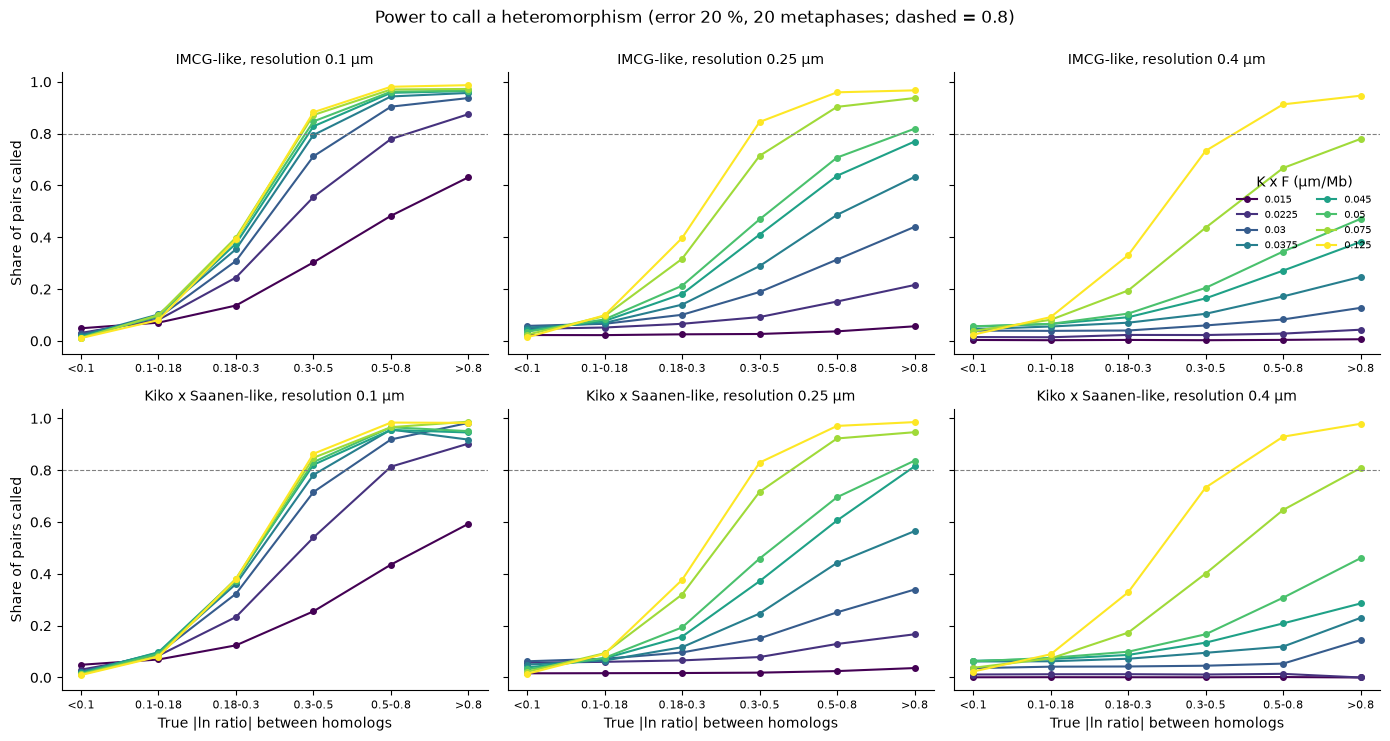

In [18]:
labels = ['<0.1', '0.1-0.18', '0.18-0.3', '0.3-0.5', '0.5-0.8', '>0.8']
ref = power[(power.error == 0.20) & (power.metaphases == 20)]
cmap = plt.get_cmap('viridis'); kfs = sorted(power.KF.unique()); norm = plt.Normalize(0, len(kfs) - 1)
fig, axes = plt.subplots(2, 3, figsize=(14, 7.4), sharey=True)
for r, hn in enumerate(SIG_HET):
    for c, res in enumerate((0.1, 0.25, 0.4)):
        ax = axes[r, c]
        g = ref[(ref.het == hn) & (ref.res == res)].groupby('KF')[pcols].mean()
        for KF, row in g.iterrows():
            ax.plot(range(6), row.values, marker='o', ms=4, color=cmap(norm(kfs.index(KF))), label=f'{KF:.3g}')
        ax.axhline(0.8, color='gray', lw=.8, ls='--'); ax.set_xticks(range(6)); ax.set_xticklabels(labels, fontsize=8)
        ax.set_title(f'{hn}, resolution {res} µm', fontsize=10)
        if c == 0: ax.set_ylabel('Share of pairs called')
        if r == 1: ax.set_xlabel('True |ln ratio| between homologs')
        for sp in ('top', 'right'): ax.spines[sp].set_visible(False)
axes[0, 2].legend(title='K x F (µm/Mb)', frameon=False, fontsize=7, ncol=2, loc='center right')
fig.suptitle('Power to call a heteromorphism (error 20 %, 20 metaphases; dashed = 0.8)', y=0.995)
plt.tight_layout(); fig.savefig(FIG/'sim_power_curves.png', dpi=150); plt.show()

In [19]:
def min_detectable(row, thr=0.8):
    # lowest bin from which power stays at or above thr in every bin above it (bins without true pairs are skipped)
    v = [(lo, row[f'power_{lo}-{hi}']) for lo, hi in zip(EDGES[:-1], EDGES[1:])]
    for i in range(len(v)):
        later = [p for _, p in v[i:] if not np.isnan(p)]
        if later and all(p >= thr for p in later): return v[i][0]
    return np.nan
power['min_detectable_from'] = power.apply(min_detectable, axis=1)
tab = (power[(power.error == 0.20) & (power.metaphases == 20)]
       .pivot_table(index=['het', 'KF'], columns='res', values='min_detectable_from', aggfunc='mean'))
tab.columns = [f'res {c} µm' for c in tab.columns]
power.round(4).to_csv(OUT/'sim_power_by_true_difference.csv', index=False)
tab

res 0.1 µm  res 0.25 µm  res 0.4 µm
het                KF                                         
IMCG-like          0.0225         0.8          NaN         NaN
                   0.0300         0.5          NaN         NaN
                   0.0375         0.5          NaN         NaN
                   0.0450         0.3          NaN         NaN
                   0.0500         0.3          0.8         NaN
                   0.0750         0.3          0.5         NaN
                   0.1250         0.3          0.3         0.5
Kiko x Saanen-like 0.0225         0.5          NaN         NaN
                   0.0300         0.5          NaN         NaN
                   0.0375         0.5          NaN         NaN
                   0.0450         0.3          0.8         NaN
                   0.0500         0.3          0.8         NaN
                   0.0750         0.3          0.5         0.8
                   0.1250         0.3          0.3         0.5

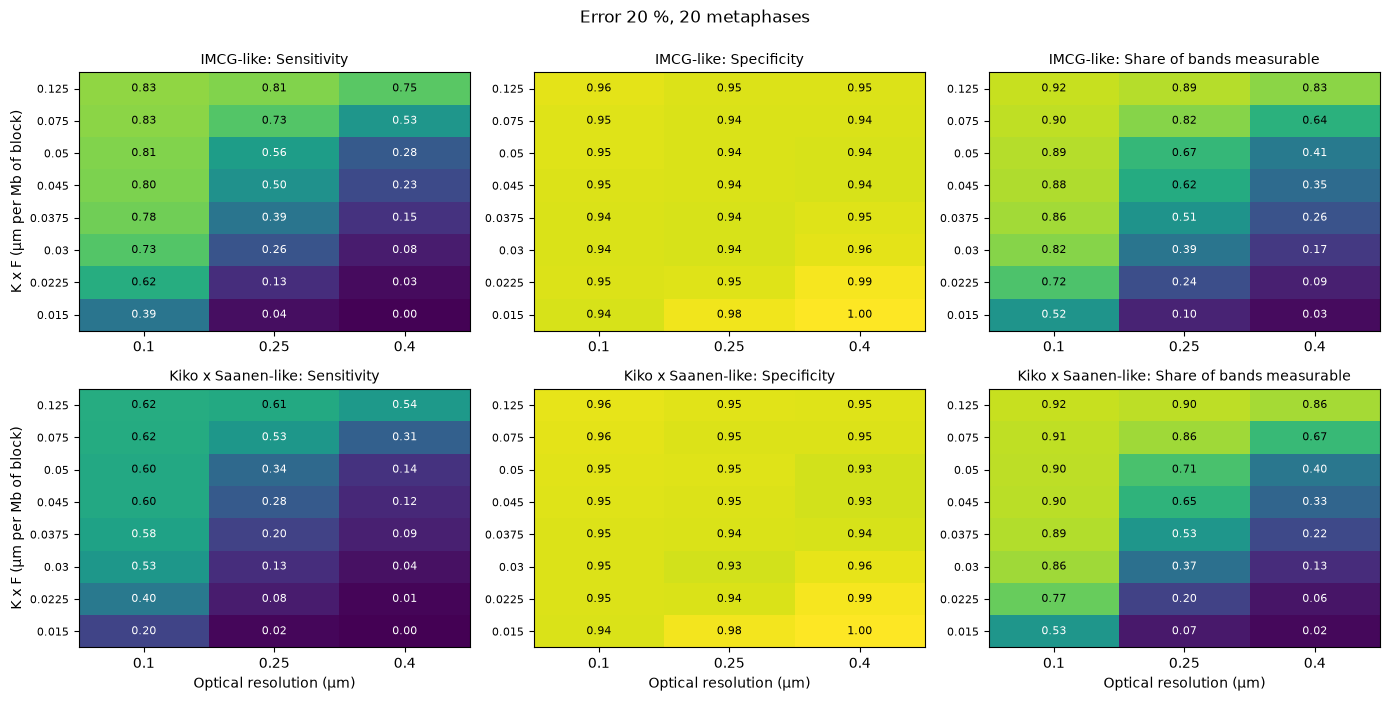

In [20]:
sub = agg[(agg.error == 0.20) & (agg.metaphases == 20)].groupby(['het', 'KF', 'res'])[['sens', 'spec', 'measurable']].mean().reset_index()
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for r, hn in enumerate(SIG_HET):
    for c, (metric, title) in enumerate((('sens', 'Sensitivity'), ('spec', 'Specificity'), ('measurable', 'Share of bands measurable'))):
        g = sub[sub.het == hn].pivot(index='KF', columns='res', values=metric)
        ax = axes[r, c]; im = ax.imshow(g.values, vmin=0, vmax=1, cmap='viridis', aspect='auto', origin='lower')
        for i in range(g.shape[0]):
            for j in range(g.shape[1]):
                ax.text(j, i, f'{g.values[i, j]:.2f}', ha='center', va='center', fontsize=8, color='white' if g.values[i, j] < .6 else 'black')
        ax.set_xticks(range(g.shape[1])); ax.set_xticklabels(g.columns); ax.set_yticks(range(g.shape[0])); ax.set_yticklabels([f'{k:.3g}' for k in g.index], fontsize=8)
        ax.set_title(f'{hn}: {title}', fontsize=10)
        if c == 0: ax.set_ylabel('K x F (µm per Mb of block)')
        if r == 1: ax.set_xlabel('Optical resolution (µm)')
fig.suptitle('Error 20 %, 20 metaphases', y=0.995)
plt.tight_layout(); fig.savefig(FIG/'sim_sensitivity_specificity.png', dpi=150); plt.show()

### 3c. Does the ground truth matter?

The reference scenario (K = 0.03, F = 1.5, resolution 0.25 µm, error 20 %, 20 metaphases) is run again with the truth built without the doubtful blocks and with the spread of the true difference taken from all usable pairs, to see whether those choices move the result.

In [21]:
def variant(name, tr, sig):
    out = []
    for hn in sig:
        rng = np.random.default_rng([SEED, 999, len(out), len(name)])
        rr = pd.DataFrame([run(tr, 0.03, 1.5, 0.25, 0.20, 20, hn, sig, rng) for _ in range(N_REP)])
        out.append(dict(variant=name, het=hn, measurable=rr.measurable.mean(), sens=rr.sens.mean(), spec=rr.spec.mean(),
                        rho_band=rr.rho_band.median(), slope_bias=rr.bias.mean()))
    return out
sig_all = {r.het: (r.sigma_cen, r.sigma_rest) for r in SIG[SIG.based_on == 'all usable pairs'].itertuples()}
sens_tab = pd.DataFrame(variant('base (all usable blocks, sigma from firm pairs)', truth, SIG_HET)
                        + variant('without doubtful blocks, sigma from all usable pairs', build_truth(drop_doubtful=True), sig_all))
sens_tab.round(3).to_csv(OUT/'sim_sensitivity_truth.csv', index=False)
sens_tab.round(3)

,variant,het,measurable,sens,spec,rho_band,slope_bias
0,"base (all usable blocks, sigma from firm pairs)",IMCG-like,0.617,0.499,0.945,0.269,0.127
1,"base (all usable blocks, sigma from firm pairs)",Kiko x Saanen-like,0.650,0.286,0.949,0.317,0.153
2,"without doubtful blocks, sigma from all usable...",IMCG-like,0.611,0.485,0.946,0.343,0.137
3,"without doubtful blocks, sigma from all usable...",Kiko x Saanen-like,0.641,0.272,0.947,0.389,0.160


In [22]:
ref_rows = agg[(agg.K == 0.03) & (agg.F == 1.5) & (agg.res == 0.25) & (agg.error == 0.20) & (agg.metaphases == 20)]
print('Reference scenario (K=0.03, F=1.5, resolution 0.25 um, error 20 %, 20 metaphases):')
print(ref_rows[['het', 'measurable', 'sens', 'spec', 'rho_band', 'rho_ceiling', 'slope_bias']].round(2).to_string(index=False))
print()
for hn in SIG_HET:
    g = agg[agg.het == hn]
    ok = g[(g.sens >= 0.8) & (g.spec >= 0.9)]
    print(f'{hn}: sensitivity >= 0.8 and specificity >= 0.9 in {len(ok)} of {len(g)} scenarios; '
          f'sensitivity ranges {g.sens.min():.2f}-{g.sens.max():.2f}, specificity {g.spec.min():.2f}-{g.spec.max():.2f}')
    for res in (0.1, 0.25, 0.4):
        gg = g[g.res == res]; print(f'   resolution {res}: sensitivity median {gg.sens.median():.2f} (range {gg.sens.min():.2f}-{gg.sens.max():.2f}); bands measurable median {gg.measurable.median():.2f}')
print()
print('Concordance with sequence (Spearman), median over scenarios: band %.2f, ceiling %.2f; FISH SatI %.2f, SatII %.2f, SatIII %.2f'
      % (agg.rho_band.median(), agg.rho_ceiling.median(), agg.rho_FISH_SatI.median(), agg.rho_FISH_SatII.median(), agg.rho_FISH_SatIII.median()))
print('Slope bias (estimated - true), median %.2f, range %.2f to %.2f' % (agg.slope_bias.median(), agg.slope_bias.min(), agg.slope_bias.max()))

Reference scenario (K=0.03, F=1.5, resolution 0.25 um, error 20 %, 20 metaphases):
               het  measurable  sens  spec  rho_band  rho_ceiling  slope_bias
         IMCG-like        0.62  0.50  0.94      0.28         0.31        0.12
Kiko x Saanen-like        0.65  0.28  0.95      0.31         0.34        0.15

IMCG-like: sensitivity >= 0.8 and specificity >= 0.9 in 20 of 162 scenarios; sensitivity ranges 0.00-0.85, specificity 0.83-1.00
   resolution 0.1: sensitivity median 0.77 (range 0.36-0.85); bands measurable median 0.88
   resolution 0.25: sensitivity median 0.48 (range 0.02-0.83); bands measurable median 0.62
   resolution 0.4: sensitivity median 0.22 (range 0.00-0.77); bands measurable median 0.35
Kiko x Saanen-like: sensitivity >= 0.8 and specificity >= 0.9 in 0 of 162 scenarios; sensitivity ranges 0.00-0.64, specificity 0.83-1.00
   resolution 0.1: sensitivity median 0.56 (range 0.19-0.64); bands measurable median 0.90
   resolution 0.25: sensitivity median 0.30 (range 